Load and prepare the datasets

Import the required libraries

In [ ]:
# Import libraries for data analysis, visualisation and modelling

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from IPython.display import display
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# Set a consistent visualisation style
sns.set_theme(style="whitegrid")

# Make displayed tables easier to read
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully.")

Libraries imported successfully.


Upload the two files to Google Colab

In [ ]:
# Upload recruiter A and recruiter B datasets

from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving recruiter_A.csv to recruiter_A.csv
Saving recruiter_B.xlsx to recruiter_B.xlsx
Uploaded files:
recruiter_A.csv
recruiter_B.xlsx


Load both datasets

In [ ]:
# Read the CSV and Excel files

csv_file = next(
    (f for f in uploaded if f.lower().endswith(".csv")),
    None
)

excel_file = next(
    (f for f in uploaded if f.lower().endswith((".xlsx", ".xls"))),
    None
)

if csv_file is None or excel_file is None:
    raise FileNotFoundError(
        "Please upload both a CSV file and an Excel file."
    )

recruiter_A = pd.read_csv(csv_file)
recruiter_B = pd.read_excel(excel_file)

print("Recruiter A shape:", recruiter_A.shape)
print("Recruiter B shape:", recruiter_B.shape)

print("\nRecruiter A preview:")
display(recruiter_A.head())

print("\nRecruiter B preview:")
display(recruiter_B.head())

Recruiter A shape: (4000, 12)
Recruiter B shape: (4000, 12)

Recruiter A preview:


,student_id,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome
0,A00001,59.1,59.3,2.94,State,Humanities,47.3,0,Female,Other,NaN,1
1,A00002,80.0,78.0,3.60,State,Humanities,49.9,1,Male,Mixed,NaN,1
2,A00003,72.8,60.4,3.31,State,Arts,145.9,0,Male,Asian,NaN,1
3,A00004,54.9,60.7,3.52,State,STEM,63.1,0,Female,White,NaN,1
4,A00005,64.2,56.8,2.99,State,Arts,175.9,1,Male,Black,NaN,1



Recruiter B preview:


,student_id,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome
0,B00001,61.3,76.1,3.80,State,Arts,95.6,0,Female,Other,NaN,0
1,B00002,56.6,60.9,2.81,State,Humanities,80.9,0,Female,Other,NaN,1
2,B00003,72.4,73.5,3.56,Independent,STEM,70.5,1,Male,White,NaN,1
3,B00004,76.3,75.4,2.46,State,Social Sciences,118.4,0,Male,Other,NaN,1
4,B00005,65.1,57.8,3.75,State,Humanities,88.3,1,Female,White,Learning,1


Inspect column names and data types

In [ ]:
# Check whether both datasets have compatible structures

print("Recruiter A columns:")
print(recruiter_A.columns.tolist())

print("\nRecruiter B columns:")
print(recruiter_B.columns.tolist())

print("\nRecruiter A data types:")
print(recruiter_A.dtypes)

print("\nRecruiter B data types:")
print(recruiter_B.dtypes)

if set(recruiter_A.columns) != set(recruiter_B.columns):
    raise ValueError(
        "The datasets have different column names. "
        "Investigate the differences before merging."
    )

# Align the column order
recruiter_B = recruiter_B[recruiter_A.columns]

print("\nDataset structures are compatible.")

Recruiter A columns:
['student_id', 'prior_attainment_score', 'admissions_test_score', 'personal_statement_score', 'school_type', 'intended_subject_area', 'distance_from_campus_km', 'first_generation_student', 'gender', 'ethnicity', 'disability_status', 'admission_outcome']

Recruiter B columns:
['student_id', 'prior_attainment_score', 'admissions_test_score', 'personal_statement_score', 'school_type', 'intended_subject_area', 'distance_from_campus_km', 'first_generation_student', 'gender', 'ethnicity', 'disability_status', 'admission_outcome']

Recruiter A data types:
student_id                   object
prior_attainment_score      float64
admissions_test_score       float64
personal_statement_score    float64
school_type                  object
intended_subject_area        object
distance_from_campus_km     float64
first_generation_student      int64
gender                       object
ethnicity                    object
disability_status            object
admission_outcome           

Add recruiter identifiers and combine the data

In [ ]:
# Preserve the origin of each applicant record

recruiter_A = recruiter_A.copy()
recruiter_B = recruiter_B.copy()

recruiter_A["recruiter"] = "Recruiter A"
recruiter_B["recruiter"] = "Recruiter B"

# Combine both datasets vertically
df = pd.concat(
    [recruiter_A, recruiter_B],
    ignore_index=True
)

print("Combined dataset shape:", df.shape)
print("Total applications:", len(df))

print("\nApplications by recruiter:")
display(df["recruiter"].value_counts().rename("applications"))

display(df.head())

Combined dataset shape: (8000, 13)
Total applications: 8000

Applications by recruiter:


,applications
recruiter,
Recruiter A,4000
Recruiter B,4000


,student_id,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome,recruiter
0,A00001,59.1,59.3,2.94,State,Humanities,47.3,0,Female,Other,NaN,1,Recruiter A
1,A00002,80.0,78.0,3.60,State,Humanities,49.9,1,Male,Mixed,NaN,1,Recruiter A
2,A00003,72.8,60.4,3.31,State,Arts,145.9,0,Male,Asian,NaN,1,Recruiter A
3,A00004,54.9,60.7,3.52,State,STEM,63.1,0,Female,White,NaN,1,Recruiter A
4,A00005,64.2,56.8,2.99,State,Arts,175.9,1,Male,Black,NaN,1,Recruiter A


Check missing values, duplicates and unique IDs

In [ ]:
# Conduct initial data-quality checks

print("Missing values by column:")
display(df.isnull().sum().to_frame("missing_values"))

print("\nMissing-value percentages:")
display(
    (df.isnull().mean() * 100)
    .round(2)
    .to_frame("missing_percentage")
)

print("\nFull duplicate rows:", df.duplicated().sum())

print("Duplicate applicant IDs:", df["student_id"].duplicated().sum())

print("\nRecords by recruiter:")
display(df["recruiter"].value_counts())

print("\nTarget variable counts:")
display(df["admission_outcome"].value_counts(dropna=False))

Missing values by column:


,missing_values
student_id,0
prior_attainment_score,0
admissions_test_score,0
personal_statement_score,0
school_type,1
intended_subject_area,1
distance_from_campus_km,1
first_generation_student,0
gender,0
ethnicity,0



Missing-value percentages:


,missing_percentage
student_id,0.00
prior_attainment_score,0.00
admissions_test_score,0.00
personal_statement_score,0.00
school_type,0.01
intended_subject_area,0.01
distance_from_campus_km,0.01
first_generation_student,0.00
gender,0.00
ethnicity,0.00



Full duplicate rows: 0
Duplicate applicant IDs: 0

Records by recruiter:


,count
recruiter,
Recruiter A,4000
Recruiter B,4000



Target variable counts:


,count
admission_outcome,
1,4850
0,3150


Clean identifiers and validate target values

In [ ]:
# Standardise identifier formatting and validate key fields

df["student_id"] = df["student_id"].astype("string").str.strip()

# Check whether IDs are missing or duplicated
if df["student_id"].isna().any():
    raise ValueError("Missing student IDs must be investigated.")

if df["student_id"].duplicated().any():
    raise ValueError(
        "Duplicate student IDs detected. Investigate before modelling."
    )

# Validate the binary target variable
valid_target = df["admission_outcome"].isin([0, 1])

if not valid_target.all():
    print("Invalid target records:")
    display(df.loc[~valid_target])

    # Exclude records with invalid target labels from supervised modelling
    df = df.loc[valid_target].copy()

df["admission_outcome"] = df["admission_outcome"].astype(int)

print("Unique applicant IDs:", df["student_id"].nunique())
print("Records available for analysis:", len(df))
print("Target validation completed.")

Unique applicant IDs: 8000
Records available for analysis: 8000
Target validation completed.


Data cleaning and validation

Inspect unexpected category values

In [ ]:
# Inspect categorical variables before standardisation

categorical_columns = [
    "school_type",
    "intended_subject_area",
    "gender",
    "ethnicity",
    "disability_status"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


school_type:
school_type
State            5205
Independent      1957
International     834
S                   2
I                   1
NaN                 1
Name: count, dtype: int64

intended_subject_area:
intended_subject_area
Social Sciences    2019
STEM               1997
Arts               1992
Humanities         1989
Soc                   1
A                     1
NaN                   1
Name: count, dtype: int64

gender:
gender
Female    4026
Male      3806
Other      164
M            2
F            2
Name: count, dtype: int64

ethnicity:
ethnicity
Other    1633
Mixed    1614
Asian    1597
Black    1593
White    1563
Name: count, dtype: int64

disability_status:
disability_status
NaN         6210
Learning     807
Mental       492
Physical     491
Name: count, dtype: int64


Standardise confirmed category labels

In [ ]:
# Cell 9: Standardise category labels using confirmed mappings.
# Review Cell 8 first. Do not map an abbreviation if its meaning is uncertain.

category_mappings = {
    "school_type": {
        "S": "State",
        "I": "Independent"
    },
    "intended_subject_area": {
        "Soc": "Social Sciences",
        "A": "Arts"
    },
    "gender": {
        "M": "Male",
        "F": "Female"
    },
    "disability_status": {
        "Mental": "Mental Health"
    }
}

for column, mapping in category_mappings.items():
    df[column] = df[column].replace(mapping)

# Remove leading/trailing spaces in categorical fields
for column in categorical_columns:
    df[column] = df[column].apply(
        lambda value: value.strip() if isinstance(value, str) else value
    )

print("Category standardisation completed.")

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))

Category standardisation completed.

school_type:
school_type
State            5207
Independent      1958
International     834
NaN                 1
Name: count, dtype: int64

intended_subject_area:
intended_subject_area
Social Sciences    2020
STEM               1997
Arts               1993
Humanities         1989
NaN                   1
Name: count, dtype: int64

gender:
gender
Female    4028
Male      3808
Other      164
Name: count, dtype: int64

ethnicity:
ethnicity
Other    1633
Mixed    1614
Asian    1597
Black    1593
White    1563
Name: count, dtype: int64

disability_status:
disability_status
NaN              6210
Learning          807
Mental Health     492
Physical          491
Name: count, dtype: int64


Validate numerical ranges

In [ ]:
# Identify numerical values outside expected ranges

expected_ranges = {
    "prior_attainment_score": (0, 100),
    "admissions_test_score": (0, 100),
    "personal_statement_score": (1, 5),
    "distance_from_campus_km": (0, None)
}

for column, (lower, upper) in expected_ranges.items():

    invalid = pd.Series(False, index=df.index)

    if lower is not None:
        invalid |= df[column].notna() & (df[column] < lower)

    if upper is not None:
        invalid |= df[column].notna() & (df[column] > upper)

    print(f"\n{column}: {invalid.sum()} out-of-range records")

    if invalid.any():
        display(
            df.loc[invalid, ["student_id", "recruiter", column]].head(20)
        )


prior_attainment_score: 4 out-of-range records


,student_id,recruiter,prior_attainment_score
731,A00732,Recruiter A,105.7
3640,A03641,Recruiter A,100.5
4328,B00329,Recruiter B,100.8
6550,B02551,Recruiter B,103.5



admissions_test_score: 10 out-of-range records


,student_id,recruiter,admissions_test_score
731,A00732,Recruiter A,101.5
2386,A02387,Recruiter A,101.0
2702,A02703,Recruiter A,100.1
3558,A03559,Recruiter A,104.7
4806,B00807,Recruiter B,101.0
5441,B01442,Recruiter B,101.3
5629,B01630,Recruiter B,100.2
5673,B01674,Recruiter B,101.0
5987,B01988,Recruiter B,100.4
7839,B03840,Recruiter B,100.5



personal_statement_score: 133 out-of-range records


,student_id,recruiter,personal_statement_score
83,A00084,Recruiter A,5.06
173,A00174,Recruiter A,5.38
209,A00210,Recruiter A,5.45
252,A00253,Recruiter A,5.36
287,A00288,Recruiter A,6.45
304,A00305,Recruiter A,5.25
329,A00330,Recruiter A,5.43
384,A00385,Recruiter A,5.12
392,A00393,Recruiter A,0.87
420,A00421,Recruiter A,5.02



distance_from_campus_km: 0 out-of-range records


Correct invalid numerical entries without inventing values

In [ ]:
# Cell 11: Preserve the original data and flag invalid measurements

df["prior_attainment_score_original"] = df["prior_attainment_score"]
df["admissions_test_score_original"] = df["admissions_test_score"]
df["personal_statement_score_original"] = df["personal_statement_score"]
df["distance_from_campus_km_original"] = df["distance_from_campus_km"]

# Flag scores outside the specified assessment ranges
df["invalid_prior_attainment"] = (
    ~df["prior_attainment_score"].between(0, 100)
)

df["invalid_admissions_test"] = (
    ~df["admissions_test_score"].between(0, 100)
)

df["invalid_personal_statement"] = (
    ~df["personal_statement_score"].between(1, 5)
)

df["invalid_distance"] = (
    df["distance_from_campus_km"] < 0
)

# Set invalid measurements to missing pending investigation.
# The original values remain available in the *_original columns.
df.loc[
    df["invalid_prior_attainment"],
    "prior_attainment_score"
] = np.nan

df.loc[
    df["invalid_admissions_test"],
    "admissions_test_score"
] = np.nan

df.loc[
    df["invalid_personal_statement"],
    "personal_statement_score"
] = np.nan

df.loc[
    df["invalid_distance"],
    "distance_from_campus_km"
] = np.nan

print("Invalid-value flags:")
display(
    df[
        [
            "invalid_prior_attainment",
            "invalid_admissions_test",
            "invalid_personal_statement",
            "invalid_distance"
        ]
    ].sum().to_frame("records_flagged")
)

print("\nRemaining missing values:")
display(df.isnull().sum().to_frame("missing_values"))

Invalid-value flags:


,records_flagged
invalid_prior_attainment,4
invalid_admissions_test,10
invalid_personal_statement,133
invalid_distance,0



Remaining missing values:


,missing_values
student_id,0
prior_attainment_score,4
admissions_test_score,10
personal_statement_score,133
school_type,1
intended_subject_area,1
distance_from_campus_km,1
first_generation_student,0
gender,0
ethnicity,0


Examine outliers using boxplots

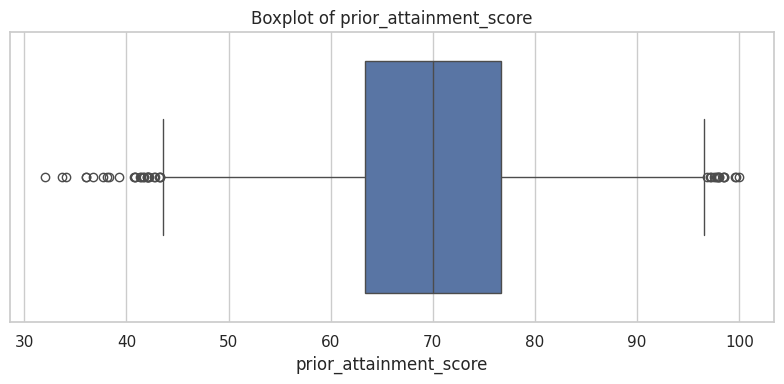

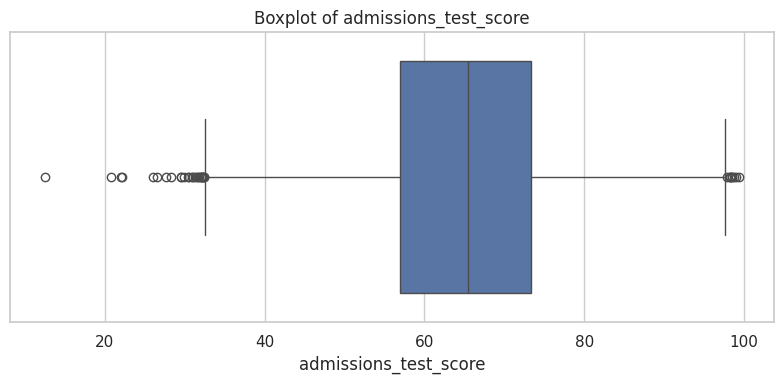

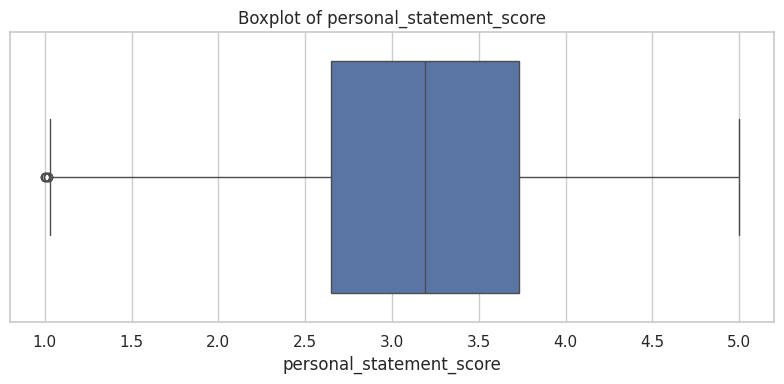

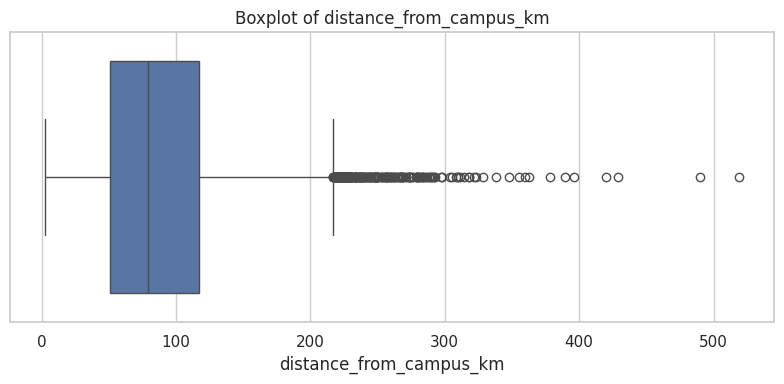

In [ ]:
# Visualise the numerical distributions and potential outliers

numerical_columns = [
    "prior_attainment_score",
    "admissions_test_score",
    "personal_statement_score",
    "distance_from_campus_km"
]

for column in numerical_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

Prepare a cleaned modelling dataset

In [ ]:
# Create a modelling copy after quality checks

# Remove exact duplicate rows if any exist.
# Applicant IDs must remain unique; conflicting duplicate IDs need investigation.
df = df.drop_duplicates().copy()

# Preserve the historical offer outcome as the target
target = "admission_outcome"

# Confirm the target has no missing values
df = df.dropna(subset=[target]).copy()

print("Cleaned analysis dataset shape:", df.shape)
print("\nMissing values after initial cleaning:")
display(df.isnull().sum().to_frame("missing_values"))

print("\nTarget distribution:")
display(df[target].value_counts())

print("\nOverall historical offer rate:")
print(f"{df[target].mean() * 100:.2f}%")

Cleaned analysis dataset shape: (8000, 21)

Missing values after initial cleaning:


,missing_values
student_id,0
prior_attainment_score,4
admissions_test_score,10
personal_statement_score,133
school_type,1
intended_subject_area,1
distance_from_campus_km,1
first_generation_student,0
gender,0
ethnicity,0



Target distribution:


,count
admission_outcome,
1,4850
0,3150



Overall historical offer rate:
60.62%


Exploratory data analysis (EDA)

Number of records

Total records: 8000
Unique student IDs: 8000


,Recruiter,Applications
0,Recruiter A,4000
1,Recruiter B,4000


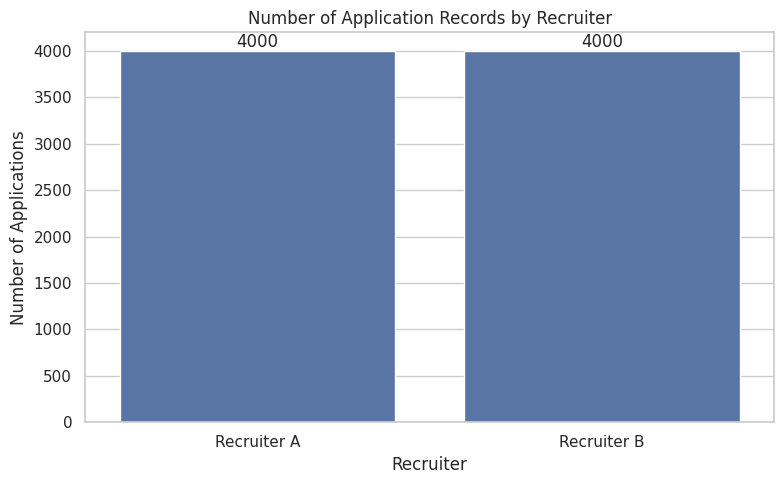

In [ ]:
# EDA 1: Number of records and applications by recruiter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

total_records = len(df)
unique_students = df["student_id"].nunique()

print("Total records:", total_records)
print("Unique student IDs:", unique_students)

recruiter_counts = (
    df["recruiter"]
    .value_counts()
    .rename_axis("Recruiter")
    .reset_index(name="Applications")
)

display(recruiter_counts)

# Graph: Number of records by recruiter
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=recruiter_counts,
    x="Recruiter",
    y="Applications"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Number of Application Records by Recruiter")
plt.xlabel("Recruiter")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

Percentage of students offered a place

Total applications: 8000
Offers: 4850
No offers: 3150
Offer percentage: 60.62%


,Outcome,Applications
0,Offer,4850
1,No offer,3150


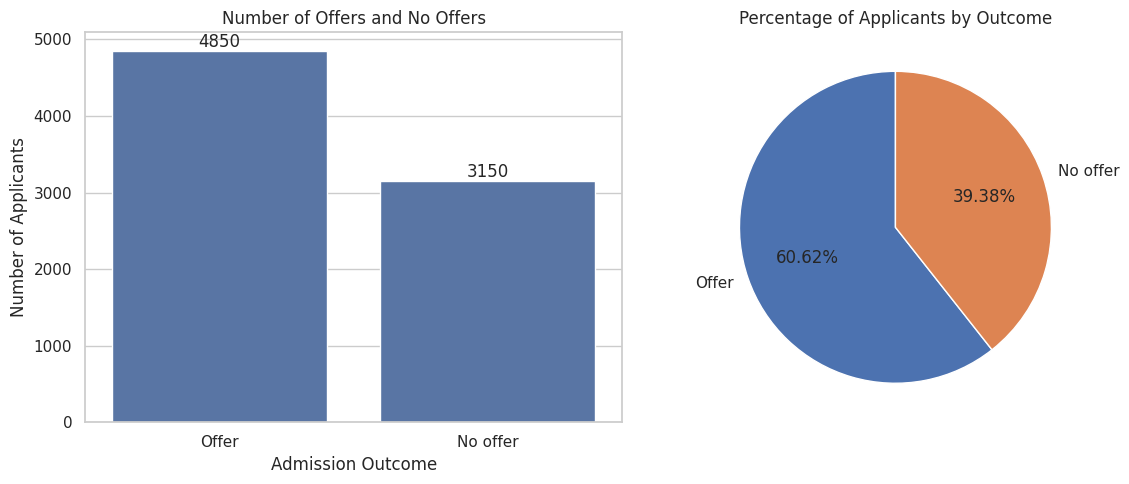

In [ ]:
# EDA 2: Overall admission outcomes

outcomes = df["admission_outcome"].dropna()

total_applications = len(outcomes)
total_offers = (outcomes == 1).sum()
total_rejections = (outcomes == 0).sum()

offer_percentage = (
    total_offers / total_applications * 100
    if total_applications > 0 else 0
)

print("Total applications:", total_applications)
print("Offers:", total_offers)
print("No offers:", total_rejections)
print(f"Offer percentage: {offer_percentage:.2f}%")

outcome_summary = pd.DataFrame({
    "Outcome": ["Offer", "No offer"],
    "Applications": [total_offers, total_rejections]
})

display(outcome_summary)

# Graph: Overall admission outcomes
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=outcome_summary,
    x="Outcome",
    y="Applications",
    ax=axes[0]
)

axes[0].set_title("Number of Offers and No Offers")
axes[0].set_xlabel("Admission Outcome")
axes[0].set_ylabel("Number of Applicants")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f")

axes[1].pie(
    outcome_summary["Applications"],
    labels=outcome_summary["Outcome"],
    autopct="%1.2f%%",
    startangle=90
)

axes[1].set_title("Percentage of Applicants by Outcome")

plt.tight_layout()
plt.show()

Comparison of places offered by gender

Admission outcomes by gender:


,gender,applications,offers,offer_rate,no_offers
0,Female,4028,2453,60.90,1575
1,Male,3808,2307,60.58,1501
2,Other,164,90,54.88,74


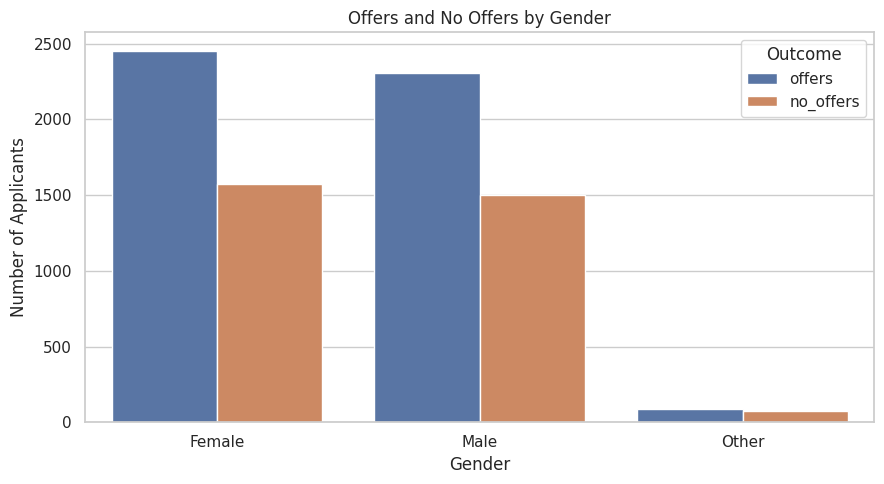

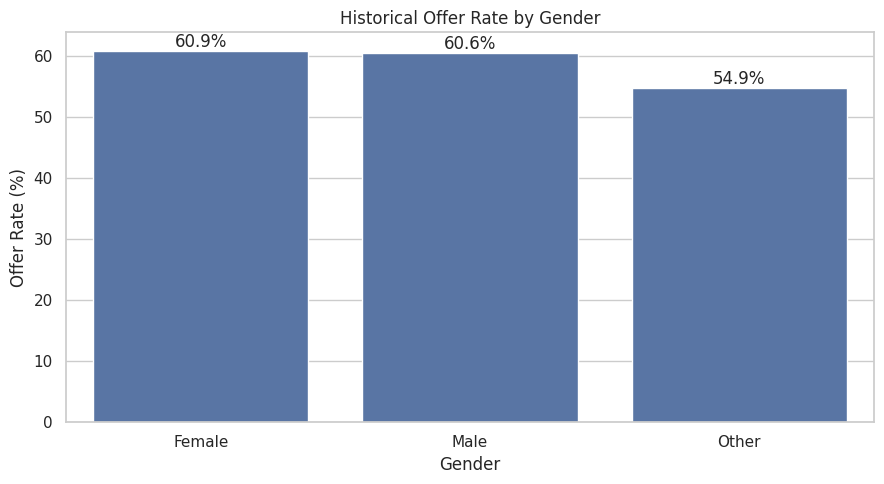

In [ ]:
# EDA 3: Applications and offers by gender

gender_outcomes = (
    df.groupby("gender", dropna=False)["admission_outcome"]
    .agg(
        applications="count",
        offers="sum",
        offer_rate="mean"
    )
    .reset_index()
)

gender_outcomes["no_offers"] = (
    gender_outcomes["applications"] - gender_outcomes["offers"]
)

gender_outcomes["offer_rate"] *= 100

print("Admission outcomes by gender:")
display(gender_outcomes.round(2))

# Graph 1: Number of offers and no offers by gender
gender_plot = gender_outcomes.melt(
    id_vars="gender",
    value_vars=["offers", "no_offers"],
    var_name="Outcome",
    value_name="Applications"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=gender_plot,
    x="gender",
    y="Applications",
    hue="Outcome"
)

plt.title("Offers and No Offers by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Applicants")
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

# Graph 2: Offer rate by gender
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=gender_outcomes,
    x="gender",
    y="offer_rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.title("Historical Offer Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Offer Rate (%)")
plt.tight_layout()
plt.show()

Number of applications by recruiter

,recruiter,number_of_applications
0,Recruiter A,4000
1,Recruiter B,4000


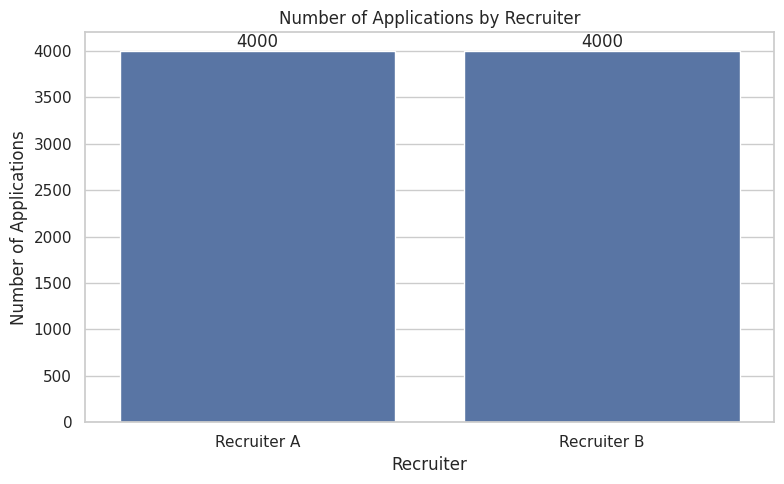

In [ ]:
# EDA 4: Application count for each recruiter

recruiter_applications = (
    df.groupby("recruiter")
    .size()
    .reset_index(name="number_of_applications")
)

display(recruiter_applications)

# Graph: Applications by recruiter
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=recruiter_applications,
    x="recruiter",
    y="number_of_applications"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Number of Applications by Recruiter")
plt.xlabel("Recruiter")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

Overall offer rate by recruiter

Recruiter offer rates:


,recruiter,applications,offers,offer_rate,no_offers
0,Recruiter A,4000,2395,59.88,1605
1,Recruiter B,4000,2455,61.38,1545


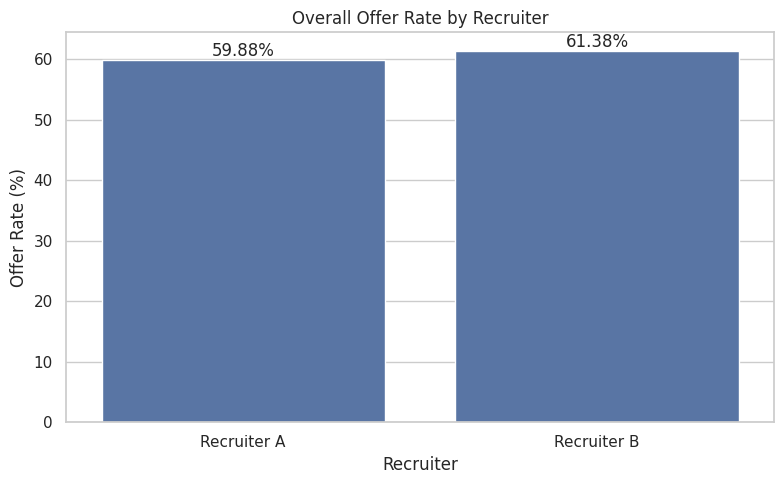

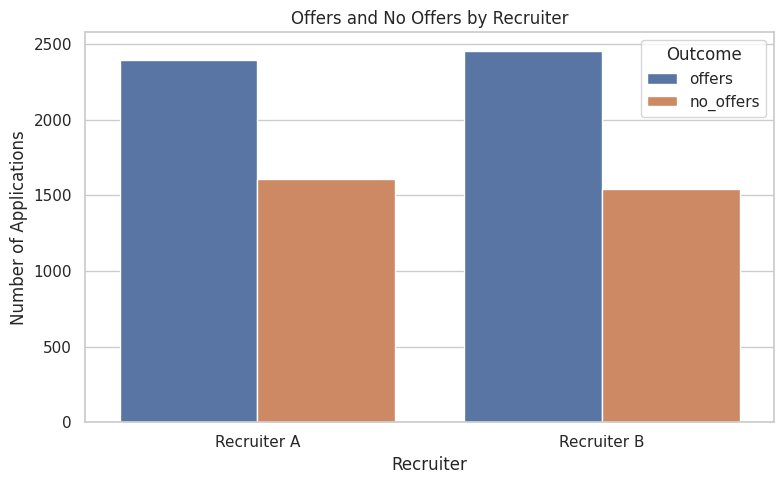

In [ ]:
# EDA 5: Calculate offer rate by recruiter

recruiter_offer_rates = (
    df.groupby("recruiter")["admission_outcome"]
    .agg(
        applications="count",
        offers="sum",
        offer_rate="mean"
    )
    .reset_index()
)

recruiter_offer_rates["no_offers"] = (
    recruiter_offer_rates["applications"]
    - recruiter_offer_rates["offers"]
)

recruiter_offer_rates["offer_rate"] *= 100

print("Recruiter offer rates:")
display(recruiter_offer_rates.round(2))

# Graph 1: Historical offer rate by recruiter
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=recruiter_offer_rates,
    x="recruiter",
    y="offer_rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Overall Offer Rate by Recruiter")
plt.xlabel("Recruiter")
plt.ylabel("Offer Rate (%)")
plt.tight_layout()
plt.show()

# Graph 2: Offers and no offers by recruiter
recruiter_outcomes_plot = recruiter_offer_rates.melt(
    id_vars="recruiter",
    value_vars=["offers", "no_offers"],
    var_name="Outcome",
    value_name="Applications"
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=recruiter_outcomes_plot,
    x="recruiter",
    y="Applications",
    hue="Outcome"
)

plt.title("Offers and No Offers by Recruiter")
plt.xlabel("Recruiter")
plt.ylabel("Number of Applications")
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

Mean and median for the required numerical variables

Mean and median:


,Mean,Median
prior_attainment_score,70.00,70.0
admissions_test_score,65.12,65.4
distance_from_campus_km,89.53,79.5


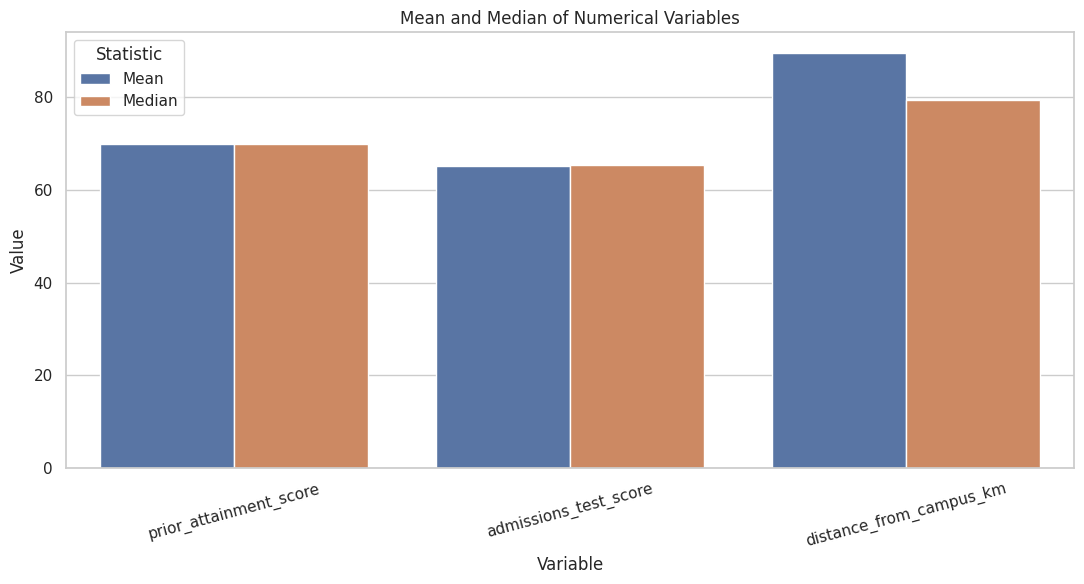

In [ ]:
# EDA 6: Mean and median statistics

required_columns = [
    "prior_attainment_score",
    "admissions_test_score",
    "distance_from_campus_km"
]

descriptive_statistics = pd.DataFrame({
    "Mean": df[required_columns].mean(),
    "Median": df[required_columns].median()
})

print("Mean and median:")
display(descriptive_statistics.round(2))

# Graph: Compare mean and median
statistics_plot = (
    descriptive_statistics
    .reset_index(names="Variable")
    .melt(
        id_vars="Variable",
        var_name="Statistic",
        value_name="Value"
    )
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=statistics_plot,
    x="Variable",
    y="Value",
    hue="Statistic"
)

plt.title("Mean and Median of Numerical Variables")
plt.xlabel("Variable")
plt.ylabel("Value")
plt.xticks(rotation=15)
plt.legend(title="Statistic")
plt.tight_layout()
plt.show()

Distribution of numerical variables

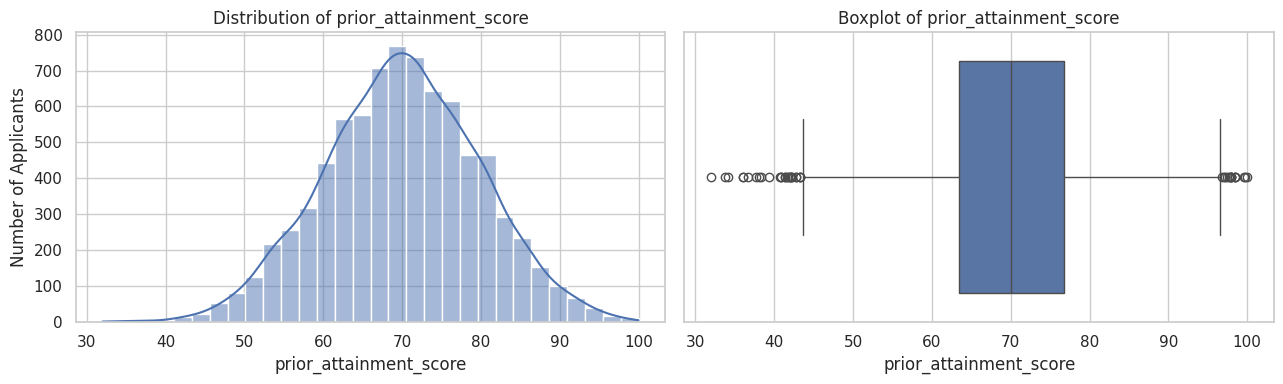

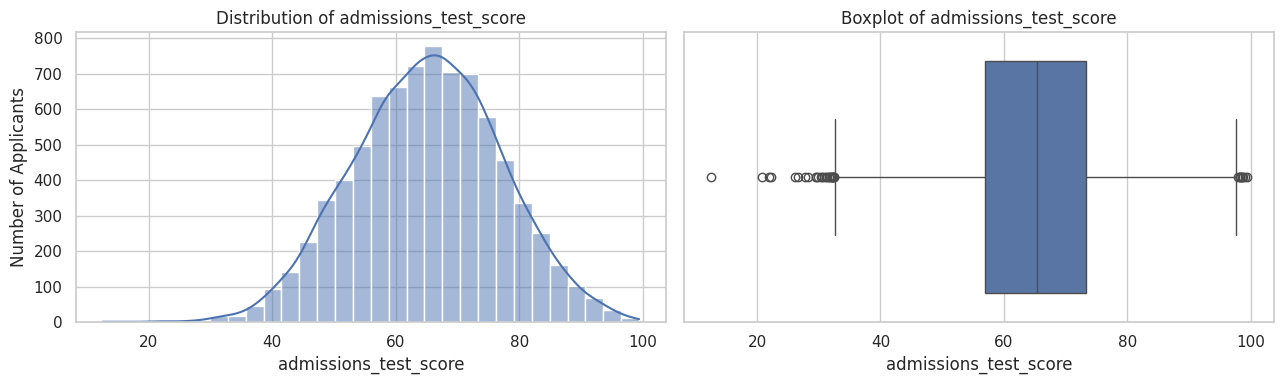

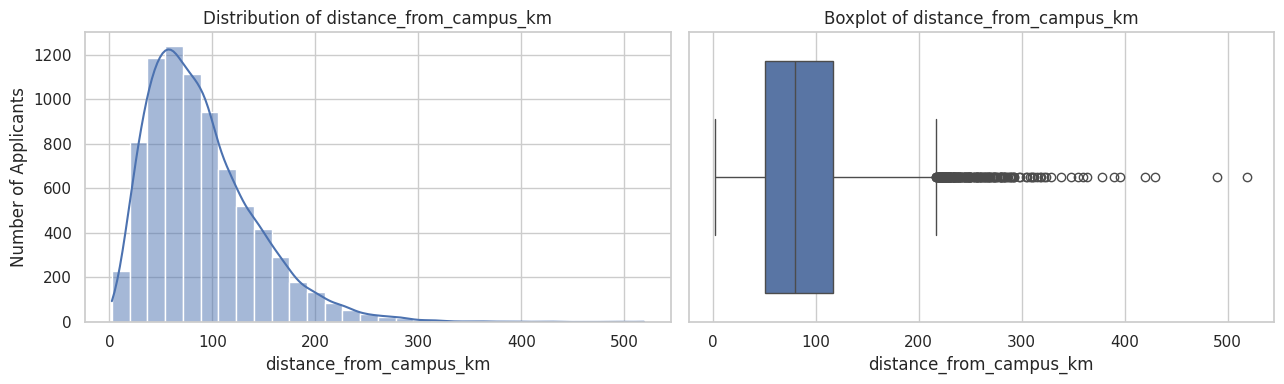

In [ ]:
# EDA 7: Histograms and boxplots for the required variables

for column in required_columns:

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 4)
    )

    sns.histplot(
        data=df,
        x=column,
        bins=30,
        kde=True,
        ax=axes[0]
    )

    axes[0].set_title(f"Distribution of {column}")
    axes[0].set_xlabel(column)
    axes[0].set_ylabel("Number of Applicants")

    sns.boxplot(
        data=df,
        x=column,
        ax=axes[1]
    )

    axes[1].set_title(f"Boxplot of {column}")
    axes[1].set_xlabel(column)

    plt.tight_layout()
    plt.show()

Relationship between prior attainment and admissions test scores

Pearson correlation coefficient: 0.014


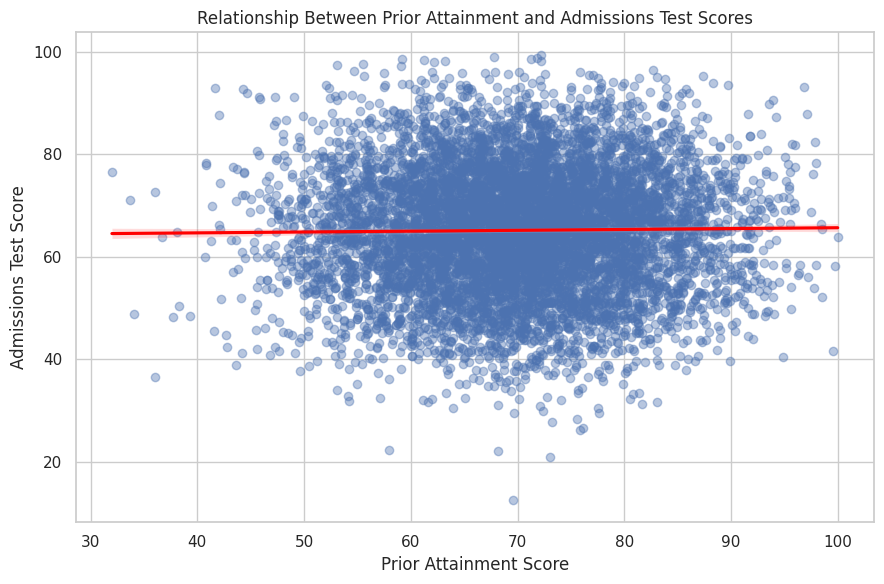

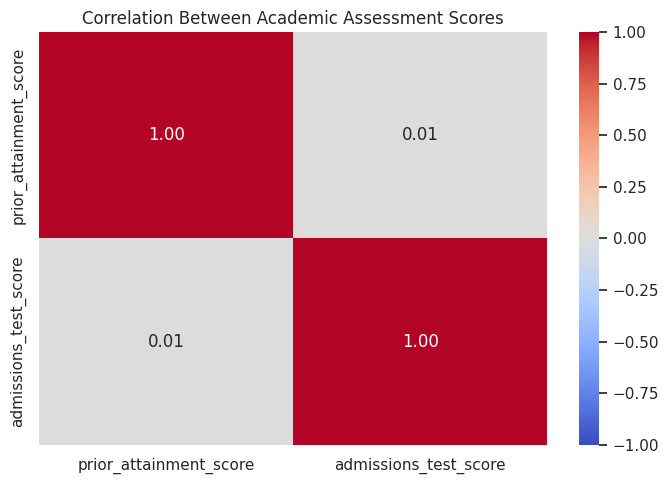

In [ ]:
# EDA 8: Relationship between academic scores

relationship_data = df[
    [
        "prior_attainment_score",
        "admissions_test_score"
    ]
].dropna()

correlation = relationship_data[
    "prior_attainment_score"
].corr(
    relationship_data["admissions_test_score"]
)

print(
    "Pearson correlation coefficient:",
    round(correlation, 3)
)

# Graph 1: Scatterplot with trend line
plt.figure(figsize=(9, 6))

sns.regplot(
    data=relationship_data,
    x="prior_attainment_score",
    y="admissions_test_score",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.title("Relationship Between Prior Attainment and Admissions Test Scores")
plt.xlabel("Prior Attainment Score")
plt.ylabel("Admissions Test Score")
plt.tight_layout()
plt.show()

# Graph 2: Correlation heatmap
plt.figure(figsize=(7, 5))

correlation_matrix = relationship_data.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Academic Assessment Scores")
plt.tight_layout()
plt.show()

Disability distribution

Distribution of Disability Status:


,disability_status,applications,percentage
0,Not Recorded,"6,210",77.62%
1,Learning,807,10.09%
2,Mental Health,492,6.15%
3,Physical,491,6.14%


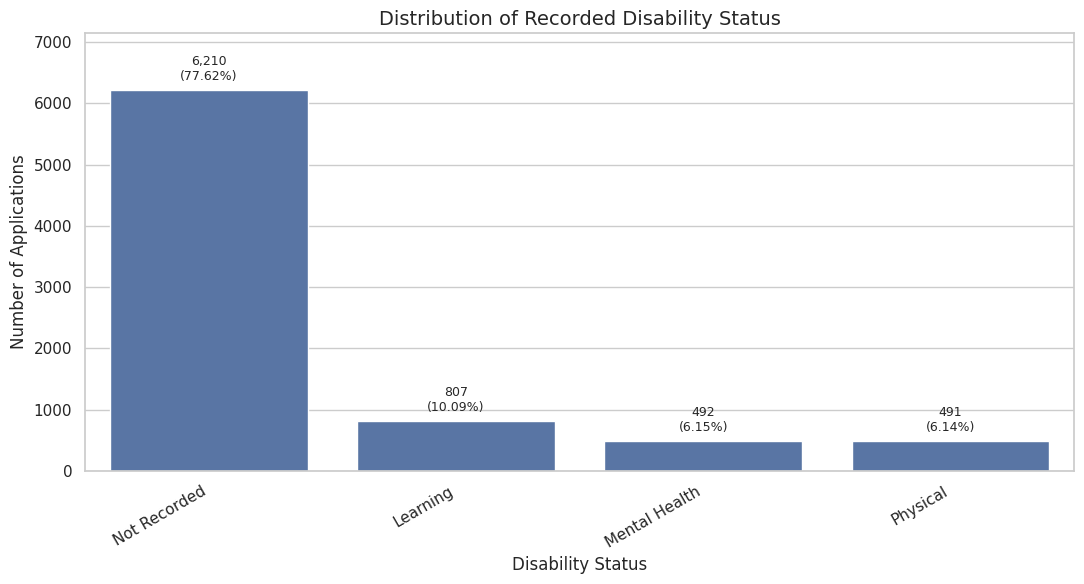

In [ ]:
# Optional EDA 9: Distribution of Recorded Disability Status

# Step 1: Calculate the disability status distribution
disability_distribution = (
    df["disability_status"]
    .value_counts(dropna=False)
    .rename_axis("disability_status")
    .reset_index(name="applications")
)

# Step 2: Calculate percentages
disability_distribution["percentage"] = (
    disability_distribution["applications"] / len(df) * 100
)

# Step 3: Replace NaN with "Not Recorded" for display and plotting
disability_distribution["disability_status"] = (
    disability_distribution["disability_status"]
    .fillna("Not Recorded")
    .astype(str)
)

# Step 4: Display the complete table
print("Distribution of Disability Status:")

display(
    disability_distribution.style.format({
        "applications": "{:,.0f}",
        "percentage": "{:.2f}%"
    })
)

# Step 5: Plot all categories, including missing values
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=disability_distribution,
    x="disability_status",
    y="applications"
)

# Step 6: Add application counts and percentages above each bar
for i, row in disability_distribution.reset_index(drop=True).iterrows():
    ax.annotate(
        f'{row["applications"]:,.0f}\n({row["percentage"]:.2f}%)',
        xy=(i, row["applications"]),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Step 7: Format the graph
plt.title("Distribution of Recorded Disability Status", fontsize=14)
plt.xlabel("Disability Status")
plt.ylabel("Number of Applications")
plt.xticks(rotation=30, ha="right")

plt.ylim(
    0,
    disability_distribution["applications"].max() * 1.15
)

plt.tight_layout()
plt.show()

Gender proportion

,gender,applications,percentage
0,Female,4028,50.35
1,Male,3808,47.60
2,Other,164,2.05


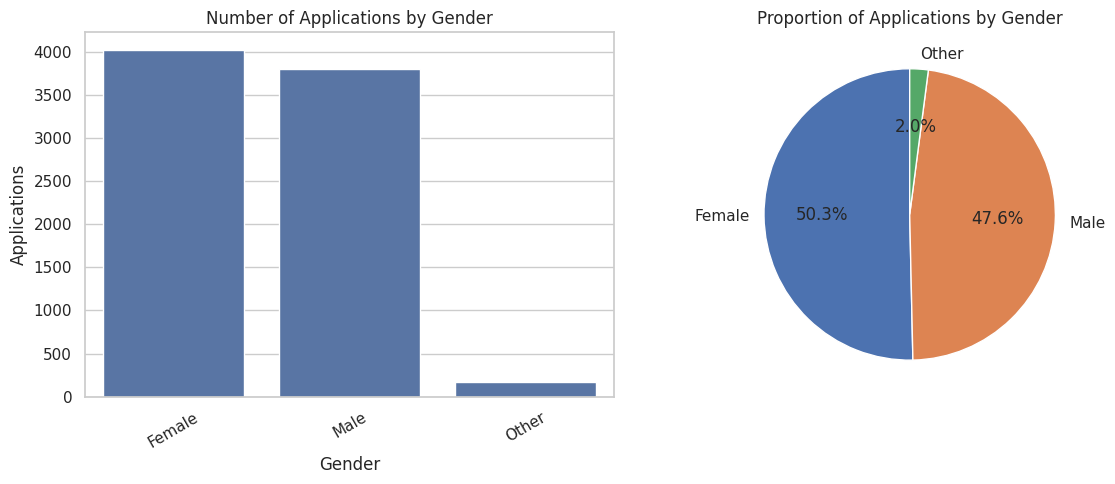

In [ ]:
# EDA 10: Gender distribution

gender_distribution = (
    df["gender"]
    .value_counts(dropna=False)
    .rename_axis("gender")
    .reset_index(name="applications")
)

gender_distribution["percentage"] = (
    gender_distribution["applications"] / len(df) * 100
)

display(gender_distribution.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=gender_distribution,
    x="gender",
    y="applications",
    ax=axes[0]
)

axes[0].set_title("Number of Applications by Gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Applications")
axes[0].tick_params(axis="x", rotation=30)

axes[1].pie(
    gender_distribution["applications"],
    labels=gender_distribution["gender"].fillna("Missing"),
    autopct="%1.1f%%",
    startangle=90
)

axes[1].set_title("Proportion of Applications by Gender")

plt.tight_layout()
plt.show()

Places offered by ethnicity

,ethnicity,applications,offers,offer_rate,no_offers
0,Asian,1597,974,60.99,623
1,Black,1593,993,62.34,600
2,Mixed,1614,985,61.03,629
3,Other,1633,974,59.64,659
4,White,1563,924,59.12,639


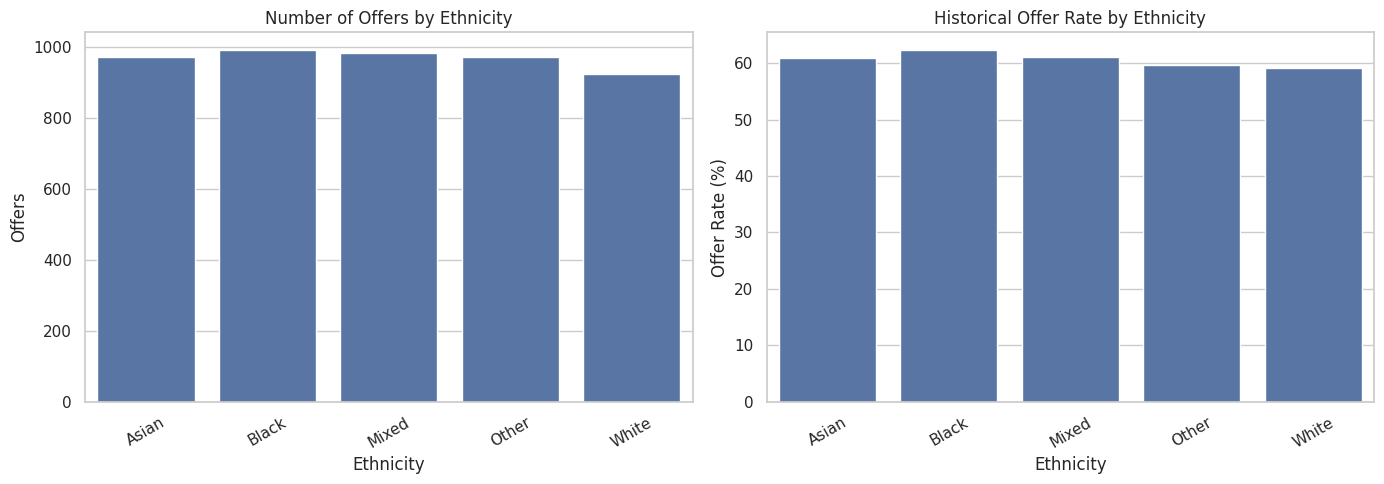

In [ ]:
# EDA 11: Historical offer outcomes by ethnicity

ethnicity_outcomes = (
    df.groupby("ethnicity", dropna=False)["admission_outcome"]
    .agg(
        applications="count",
        offers="sum",
        offer_rate="mean"
    )
    .reset_index()
)

ethnicity_outcomes["no_offers"] = (
    ethnicity_outcomes["applications"]
    - ethnicity_outcomes["offers"]
)

ethnicity_outcomes["offer_rate"] *= 100

display(ethnicity_outcomes.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=ethnicity_outcomes,
    x="ethnicity",
    y="offers",
    ax=axes[0]
)

axes[0].set_title("Number of Offers by Ethnicity")
axes[0].set_xlabel("Ethnicity")
axes[0].set_ylabel("Offers")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(
    data=ethnicity_outcomes,
    x="ethnicity",
    y="offer_rate",
    ax=axes[1]
)

axes[1].set_title("Historical Offer Rate by Ethnicity")
axes[1].set_xlabel("Ethnicity")
axes[1].set_ylabel("Offer Rate (%)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Intended subject area by gender

Application counts by subject area and gender:


gender,Female,Male,Other
intended_subject_area,,,
Arts,1004,947,42
Humanities,1011,938,40
Not recorded,1,0,0
STEM,981,975,41
Social Sciences,1031,948,41


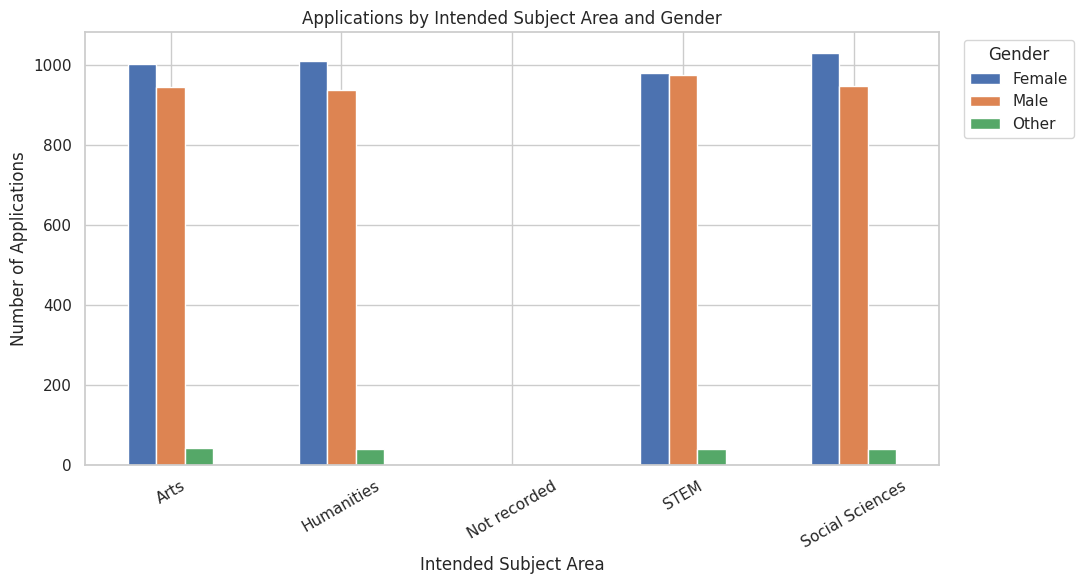

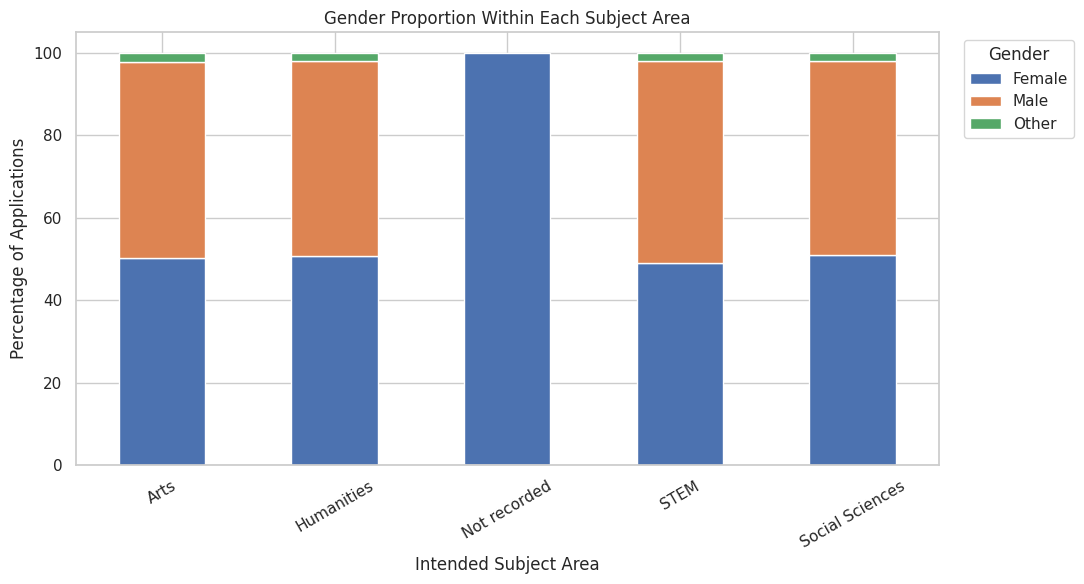

In [ ]:
# EDA 12: Compare subject areas by gender

# Create display copy and label missing subject areas
subject_gender_df = df[
    ["intended_subject_area", "gender"]
].copy()

subject_gender_df["intended_subject_area"] = (
    subject_gender_df["intended_subject_area"]
    .fillna("Not recorded")
)

# Application counts by subject area and gender
subject_gender_counts = pd.crosstab(
    subject_gender_df["intended_subject_area"],
    subject_gender_df["gender"]
)

print("Application counts by subject area and gender:")
display(subject_gender_counts)

# Graph 1: Application counts
subject_gender_counts.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Applications by Intended Subject Area and Gender")
plt.xlabel("Intended Subject Area")
plt.ylabel("Number of Applications")
plt.xticks(rotation=30)
plt.legend(
    title="Gender",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

# Graph 2: Percentage within each subject area
subject_gender_proportions = (
    pd.crosstab(
        subject_gender_df["intended_subject_area"],
        subject_gender_df["gender"],
        normalize="index"
    ) * 100
)

subject_gender_proportions.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Gender Proportion Within Each Subject Area")
plt.xlabel("Intended Subject Area")
plt.ylabel("Percentage of Applications")
plt.xticks(rotation=30)
plt.legend(
    title="Gender",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

Final EDA summary

In [ ]:
# EDA 13: Consolidated summary for the business report

print("=" * 60)
print("NORTHBRIDGE UNIVERSITY — EDA SUMMARY")
print("=" * 60)

print(f"\nTotal records: {len(df):,}")
print(f"Unique student IDs: {df['student_id'].nunique():,}")

valid_outcomes = df["admission_outcome"].dropna()

print(f"Total offers: {(valid_outcomes == 1).sum():,}")
print(f"Total no offers: {(valid_outcomes == 0).sum():,}")
print(f"Overall offer rate: {valid_outcomes.mean() * 100:.2f}%")

print("\nApplications by recruiter:")
display(recruiter_applications)

print("\nOffer rates by recruiter:")
display(recruiter_offer_rates.round(2))

print("\nOutcomes by gender:")
display(gender_outcomes.round(2))

print("\nMean and median:")
display(descriptive_statistics.round(2))

print("\nAcademic score correlation:")
print(round(correlation, 3))

print("\nEDA calculations and visualisations completed.")

NORTHBRIDGE UNIVERSITY — EDA SUMMARY

Total records: 8,000
Unique student IDs: 8,000
Total offers: 4,850
Total no offers: 3,150
Overall offer rate: 60.62%

Applications by recruiter:


,recruiter,number_of_applications
0,Recruiter A,4000
1,Recruiter B,4000



Offer rates by recruiter:


,recruiter,applications,offers,offer_rate,no_offers
0,Recruiter A,4000,2395,59.88,1605
1,Recruiter B,4000,2455,61.38,1545



Outcomes by gender:


,gender,applications,offers,offer_rate,no_offers
0,Female,4028,2453,60.90,1575
1,Male,3808,2307,60.58,1501
2,Other,164,90,54.88,74



Mean and median:


,Mean,Median
prior_attainment_score,70.00,70.0
admissions_test_score,65.12,65.4
distance_from_campus_km,89.53,79.5



Academic score correlation:
0.014

EDA calculations and visualisations completed.


Prepare the predictive modelling data

Select appropriate model features

In [ ]:
# Define predictors and target variable

features = [
    "prior_attainment_score",
    "admissions_test_score",
    "personal_statement_score"
]

target = "admission_outcome"

X = df[features].copy()
y = df[target].copy()

print("Predictive features:")
print(features)

print("\nTarget variable:", target)
print("Number of records:", len(X))

print("\nMissing predictor values:")
display(X.isnull().sum().to_frame("missing_values"))

print("\nTarget class distribution:")
display(y.value_counts(normalize=True).mul(100).round(2))

Predictive features:
['prior_attainment_score', 'admissions_test_score', 'personal_statement_score']

Target variable: admission_outcome
Number of records: 8000

Missing predictor values:


,missing_values
prior_attainment_score,4
admissions_test_score,10
personal_statement_score,133



Target class distribution:


,proportion
admission_outcome,
1,60.62
0,39.38


Split the data into training and testing sets

In [ ]:
# Create a reproducible 80/20 stratified split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining offer rate (%):", round(y_train.mean() * 100, 2))
print("Testing offer rate (%):", round(y_test.mean() * 100, 2))

Training records: 6400
Testing records: 1600

Training offer rate (%): 60.62
Testing offer rate (%): 60.62


Build the preprocessing pipeline

In [ ]:
# Impute missing academic scores and scale numerical features

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created.")
print("Missing values will be imputed using training-set medians.")
print("Numerical features will be standardised.")

Preprocessing pipeline created.
Missing values will be imputed using training-set medians.
Numerical features will be standardised.


Train two predictive models

Train Model 1: Logistic Regression

In [ ]:
# Train the Logistic Regression baseline model

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


Train Model 2: Random Forest

In [ ]:
# Train the Random Forest comparison model

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=10,
                min_samples_leaf=5,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


Evaluate both models

Generate predictions

In [ ]:
# Generate test-set predictions and predicted probabilities

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

predictions = {}
probabilities = {}

for name, model in models.items():

    predictions[name] = model.predict(X_test)

    probabilities[name] = model.predict_proba(X_test)[:, 1]

    print(f"{name}: predictions generated.")

Logistic Regression: predictions generated.
Random Forest: predictions generated.


Compare evaluation metrics

In [ ]:
# Cell 28: Evaluate the two models using multiple metrics

results = []

for name, model in models.items():

    y_pred = predictions[name]
    y_prob = probabilities[name]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Log Loss": log_loss(y_test, y_prob)
    })

metrics_df = pd.DataFrame(results)

display(
    metrics_df.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1 Score": "{:.3f}",
        "ROC-AUC": "{:.3f}",
        "Log Loss": "{:.3f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Log Loss
0,Logistic Regression,0.611,0.615,0.959,0.749,0.573,0.663
1,Random Forest,0.557,0.647,0.593,0.619,0.573,0.683


Plot the model comparison

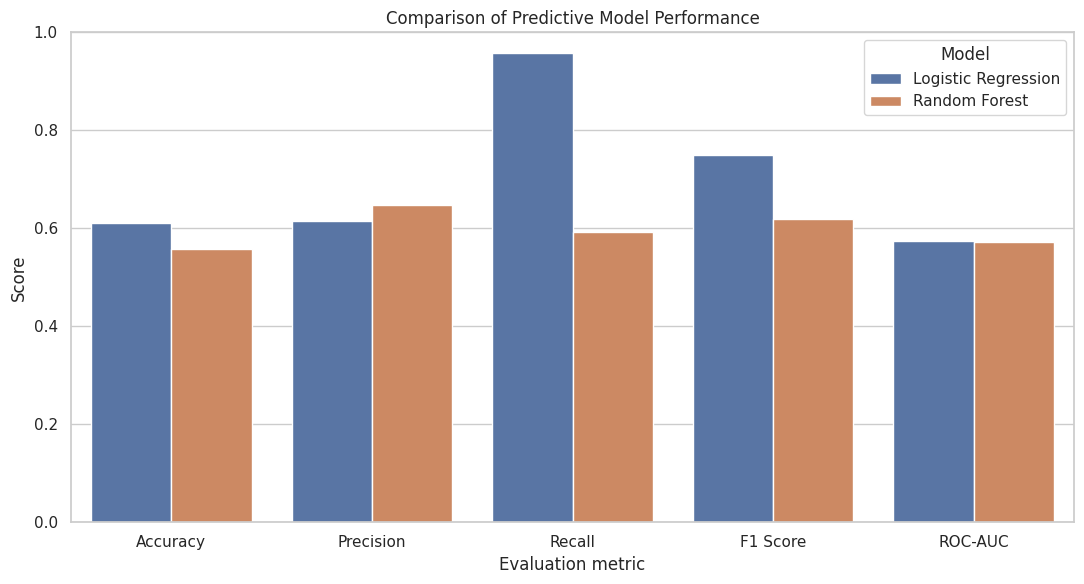

In [ ]:
# Compare the main classification metrics

comparison = metrics_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Comparison of Predictive Model Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation metric")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

Display confusion matrices

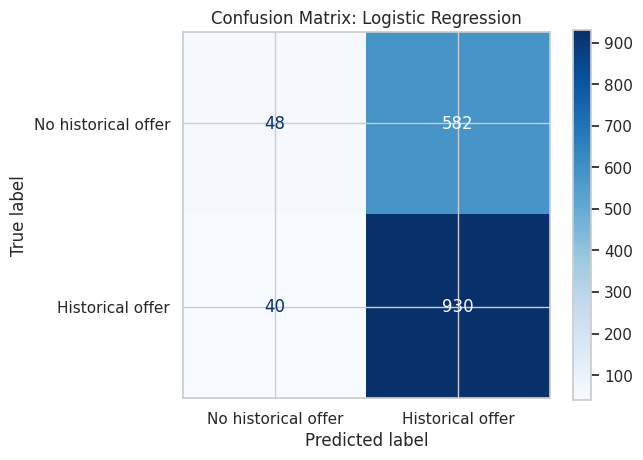


Logistic Regression classification report:
              precision    recall  f1-score   support

           0       0.55      0.08      0.13       630
           1       0.62      0.96      0.75       970

    accuracy                           0.61      1600
   macro avg       0.58      0.52      0.44      1600
weighted avg       0.59      0.61      0.51      1600



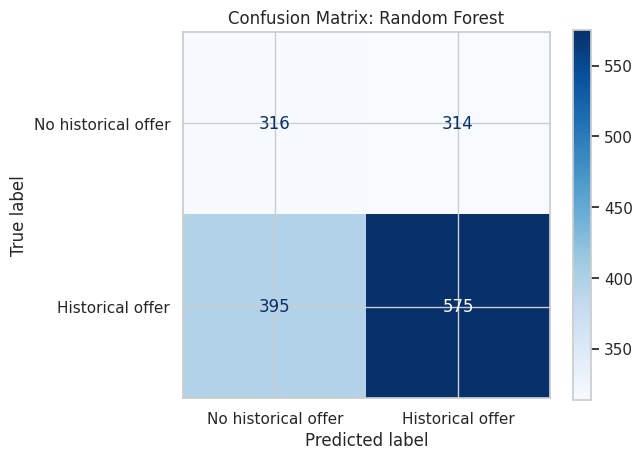


Random Forest classification report:
              precision    recall  f1-score   support

           0       0.44      0.50      0.47       630
           1       0.65      0.59      0.62       970

    accuracy                           0.56      1600
   macro avg       0.55      0.55      0.54      1600
weighted avg       0.57      0.56      0.56      1600



In [ ]:
# Compare false positives and false negatives

for name in models:

    cm = confusion_matrix(
        y_test,
        predictions[name],
        labels=[0, 1]
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No historical offer", "Historical offer"]
    )

    display_cm.plot(cmap="Blues", values_format="d")

    plt.title(f"Confusion Matrix: {name}")
    plt.tight_layout()
    plt.show()

    print(f"\n{name} classification report:")
    print(
        classification_report(
            y_test,
            predictions[name],
            zero_division=0
        )
    )

Plot ROC curves

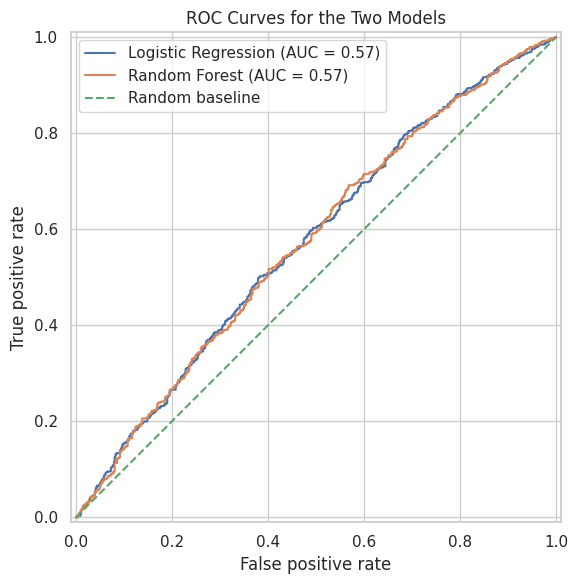

In [ ]:
# Compare discrimination performance

fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():

    RocCurveDisplay.from_predictions(
        y_test,
        probabilities[name],
        name=name,
        ax=ax
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random baseline"
)

ax.set_title("ROC Curves for the Two Models")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend()
plt.tight_layout()
plt.show()

Select a provisional model based on the results

In [ ]:
# Rank models using ROC-AUC and log loss

# ROC-AUC is maximised; log loss is minimised.
# This is a provisional technical comparison, not an admissions policy.

ranked_models = metrics_df.sort_values(
    by=["ROC-AUC", "Log Loss"],
    ascending=[False, True]
).reset_index(drop=True)

display(ranked_models)

provisional_model_name = ranked_models.loc[0, "Model"]

print("Provisional model based on the selected metrics:")
print(provisional_model_name)

print(
    "\nThis ranking must be reviewed alongside fairness, "
    "interpretability, error costs and human oversight."
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Log Loss
0,Logistic Regression,0.611250,0.615079,0.958763,0.749396,0.573315,0.663137
1,Random Forest,0.556875,0.646794,0.592784,0.618612,0.572711,0.683408


Provisional model based on the selected metrics:
Logistic Regression

This ranking must be reviewed alongside fairness, interpretability, error costs and human oversight.


Fairness and responsible-use checks

Compare model outcomes across gender

In [ ]:
# Attach test predictions to the corresponding applicant records

test_results = df.loc[
    X_test.index,
    ["student_id", "gender", "ethnicity", "recruiter", target]
].copy()

test_results["logistic_prediction"] = predictions["Logistic Regression"]
test_results["random_forest_prediction"] = predictions["Random Forest"]

test_results["logistic_probability"] = probabilities["Logistic Regression"]
test_results["random_forest_probability"] = probabilities["Random Forest"]

print("Test results prepared for fairness auditing.")
display(test_results.head())

Test results prepared for fairness auditing.


,student_id,gender,ethnicity,recruiter,admission_outcome,logistic_prediction,random_forest_prediction,logistic_probability,random_forest_probability
4696,B00697,Male,Other,Recruiter B,1,1,1,0.756680,0.847475
685,A00686,Female,Black,Recruiter A,1,1,1,0.674594,0.525022
4127,B00128,Male,Black,Recruiter B,1,1,0,0.600633,0.494741
6164,B02165,Male,Other,Recruiter B,1,0,0,0.477807,0.420812
2536,A02537,Male,Asian,Recruiter A,1,1,1,0.690528,0.515383


Calculate group-level fairness indicators

In [ ]:
# Calculate selection rates and error rates by group

def calculate_group_metrics(data, group_column, prediction_column):

    rows = []

    for group, subset in data.groupby(group_column, dropna=False):

        actual = subset[target]
        predicted = subset[prediction_column]

        rows.append({
            "Group": str(group),
            "Applications": len(subset),
            "Historical offer rate (%)": actual.mean() * 100,
            "Predicted offer rate (%)": predicted.mean() * 100,
            "Recall (%)": (
                recall_score(actual, predicted, zero_division=0) * 100
                if actual.sum() > 0 else np.nan
            ),
            "False positive rate (%)": (
                ((predicted == 1) & (actual == 0)).sum()
                / (actual == 0).sum() * 100
                if (actual == 0).sum() > 0 else np.nan
            )
        })

    return pd.DataFrame(rows)


for prediction_column in [
    "logistic_prediction",
    "random_forest_prediction"
]:

    print(f"\nFairness indicators: {prediction_column}")

    gender_fairness = calculate_group_metrics(
        test_results,
        "gender",
        prediction_column
    )

    display(gender_fairness.round(2))


Fairness indicators: logistic_prediction


,Group,Applications,Historical offer rate (%),Predicted offer rate (%),Recall (%),False positive rate (%)
0,Female,812,60.22,94.46,95.91,92.26
1,Male,757,61.29,94.45,95.69,92.49
2,Other,31,54.84,96.77,100.00,92.86



Fairness indicators: random_forest_prediction


,Group,Applications,Historical offer rate (%),Predicted offer rate (%),Recall (%),False positive rate (%)
0,Female,812,60.22,54.56,57.26,50.46
1,Male,757,61.29,56.41,60.99,49.15
2,Other,31,54.84,61.29,70.59,50.00


Examine group outcomes by ethnicity

In [ ]:
# Audit predicted outcomes across ethnicity groups

for prediction_column in [
    "logistic_prediction",
    "random_forest_prediction"
]:

    print(f"\nEthnicity fairness audit: {prediction_column}")

    ethnicity_fairness = calculate_group_metrics(
        test_results,
        "ethnicity",
        prediction_column
    )

    display(ethnicity_fairness.round(2))


Ethnicity fairness audit: logistic_prediction


,Group,Applications,Historical offer rate (%),Predicted offer rate (%),Recall (%),False positive rate (%)
0,Asian,299,61.87,94.65,96.22,92.11
1,Black,305,64.26,94.10,93.88,94.50
2,Mixed,326,59.82,92.94,94.36,90.84
3,Other,340,58.82,95.29,97.00,92.86
4,White,330,58.79,95.45,97.94,91.91



Ethnicity fairness audit: random_forest_prediction


,Group,Applications,Historical offer rate (%),Predicted offer rate (%),Recall (%),False positive rate (%)
0,Asian,299,61.87,56.19,58.92,51.75
1,Black,305,64.26,51.80,54.59,46.79
2,Mixed,326,59.82,55.83,61.03,48.09
3,Other,340,58.82,56.47,61.00,50.00
4,White,330,58.79,57.27,60.82,52.21


Code validation, export and maintenance

Validate model inputs and predictions

In [ ]:
# Run basic validation checks

assert len(X_train) + len(X_test) == len(X), (
    "Training and testing sizes do not match the original dataset."
)

assert set(y_train.unique()).issubset({0, 1}), (
    "Training target contains unexpected values."
)

assert set(y_test.unique()).issubset({0, 1}), (
    "Testing target contains unexpected values."
)

for name in models:

    assert len(predictions[name]) == len(y_test), (
        f"Prediction length mismatch for {name}."
    )

    assert np.isfinite(probabilities[name]).all(), (
        f"Invalid predicted probabilities for {name}."
    )

    assert np.all(
        (probabilities[name] >= 0) &
        (probabilities[name] <= 1)
    ), f"Probabilities outside [0, 1] for {name}."

print("All basic validation checks passed.")

All basic validation checks passed.


Export key analysis results

In [ ]:
# Export the key analysis results

from pathlib import Path
import pandas as pd

# Step 1: Create the output directory
output_dir = Path("/content/pdm_results")
output_dir.mkdir(parents=True, exist_ok=True)


# Step 2: Define the missing admission summary
# Assumes admission_outcome = 1 means offer and 0 means no offer.

if "df" not in globals():
    raise NameError(
        "The DataFrame 'df' is not defined. Run the data-loading "
        "and merging cells first."
    )

if "admission_outcome" not in df.columns:
    raise KeyError(
        "The column 'admission_outcome' is missing from df."
    )

outcomes = pd.to_numeric(
    df["admission_outcome"], errors="coerce"
)

valid_outcomes = outcomes.isin([0, 1])
valid_data = outcomes[valid_outcomes]

total_applications = len(df)
valid_applications = len(valid_data)
offers = int((valid_data == 1).sum())
non_offers = int((valid_data == 0).sum())

offer_rate = (
    valid_data.eq(1).mean() * 100
    if valid_applications > 0
    else 0
)

summary = pd.DataFrame({
    "Metric": [
        "Total applications",
        "Applications with valid outcomes",
        "Applications with missing or invalid outcomes",
        "Offers",
        "Non-offers",
        "Offer rate (%)"
    ],
    "Value": [
        total_applications,
        valid_applications,
        total_applications - valid_applications,
        offers,
        non_offers,
        round(offer_rate, 2)
    ]
})


# Step 3: Export the admission summary
summary.to_csv(
    output_dir / "admission_summary.csv",
    index=False
)


# Step 4: Export the remaining analysis results
# These DataFrames must have been created in earlier cells.

required_exports = {
    "gender_outcomes": "gender_outcomes.csv",
    "recruiter_counts": "recruiter_application_counts.csv",
    "recruiter_outcomes": "recruiter_offer_rates.csv",
    "descriptive_statistics": "descriptive_statistics.csv",
    "metrics_df": "model_evaluation_metrics.csv",
    "test_results": "test_predictions_and_fairness_data.csv"
}

missing_exports = []

for variable_name, filename in required_exports.items():

    if variable_name in globals():
        globals()[variable_name].to_csv(
            output_dir / filename,
            index=False
        )
    else:
        missing_exports.append(variable_name)


# Step 5: Report the export status
print("Admission summary exported successfully.")
print(f"Output directory: {output_dir}")

if missing_exports:
    print("\nThese DataFrames have not been created:")
    for variable_name in missing_exports:
        print(f"- {variable_name}")

    print(
        "\nRun the corresponding analysis cells before "
        "exporting these remaining results."
    )

print("\nExported files:")

for path in sorted(output_dir.iterdir()):
    if path.is_file():
        print(path.name)

Admission summary exported successfully.
Output directory: /content/pdm_results

These DataFrames have not been created:
- recruiter_outcomes

Run the corresponding analysis cells before exporting these remaining results.

Exported files:
admission_summary.csv
descriptive_statistics.csv
gender_outcomes.csv
model_evaluation_metrics.csv
recruiter_application_counts.csv
test_predictions_and_fairness_data.csv


Save the trained models

In [ ]:
# Save trained pipelines for controlled future testing

import joblib

joblib.dump(
    logistic_model,
    output_dir / "logistic_regression_pipeline.joblib"
)

joblib.dump(
    random_forest_model,
    output_dir / "random_forest_pipeline.joblib"
)

print("Both trained model pipelines have been saved.")

Both trained model pipelines have been saved.


Generate a final summary for the report

In [ ]:
# Summarise the principal findings

print("=" * 60)
print("NORTHBRIDGE UNIVERSITY – ADMISSIONS ANALYSIS")
print("=" * 60)

# 1. Overall admissions summary
print(f"Applications analysed: {len(df):,}")
print(f"Historical offers: {int(df[target].sum()):,}")
print(f"Historical offer rate: {df[target].mean() * 100:.2f}%")


# 2. Applications and offer rates by recruiter
# Create recruiter_counts if it has not already been defined.

if "recruiter" not in df.columns:
    raise KeyError(
        "The 'recruiter' column is missing from df. "
        "Run the data-merging cell first."
    )

if "recruiter_counts" not in globals():
    recruiter_counts = (
        df.groupby("recruiter")
        .size()
        .reset_index(name="Applications")
    )

# Create recruiter_outcomes if it has not already been defined.
# Only valid binary outcomes (0 and 1) are included in offer rates.

if "recruiter_outcomes" not in globals():

    valid_df = df[df[target].isin([0, 1])].copy()

    recruiter_outcomes = (
        valid_df.groupby("recruiter", dropna=False)[target]
        .agg(
            Applications="count",
            Offers="sum",
            Offer_Rate="mean"
        )
        .reset_index()
    )

    recruiter_outcomes["Offer_Rate"] *= 100


print("\nApplications by recruiter:")
print(recruiter_counts.to_string(index=False))

print("\nOffer rates by recruiter:")
print(recruiter_outcomes.round(2).to_string(index=False))


# 3. Model comparison
if "metrics_df" in globals():

    print("\nModel comparison:")
    print(metrics_df.round(3).to_string(index=False))

else:
    print("\nModel comparison unavailable.")
    print("Run the model evaluation cell to create metrics_df.")


# 4. Provisional model ranking
if "metrics_df" in globals():

    if {"Model", "ROC-AUC", "Log Loss"}.issubset(metrics_df.columns):

        ranked_models = (
            metrics_df
            .sort_values(
                by=["ROC-AUC", "Log Loss"],
                ascending=[False, True]
            )
            .reset_index(drop=True)
        )

        print("\nProvisional model ranking:")
        print(
            ranked_models[
                ["Model", "ROC-AUC", "Log Loss"]
            ].to_string(index=False)
        )

    else:
        print("\nProvisional model ranking unavailable.")
        print("Required metric columns are missing.")

else:
    print("\nProvisional model ranking unavailable.")


# 5. Responsible-use conclusion
print("\nResponsible-use conclusion:")
print(
    "Predictions describe historical offer decisions, not future academic "
    "success. Further fairness, validity and governance checks are required "
    "before any operational use."
)

NORTHBRIDGE UNIVERSITY – ADMISSIONS ANALYSIS
Applications analysed: 8,000
Historical offers: 4,850
Historical offer rate: 60.62%

Applications by recruiter:
  Recruiter  Applications
Recruiter A          4000
Recruiter B          4000

Offer rates by recruiter:
  recruiter  Applications  Offers  Offer_Rate
Recruiter A          4000    2395       59.88
Recruiter B          4000    2455       61.38

Model comparison:
              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  Log Loss
Logistic Regression     0.611      0.615   0.959     0.749    0.573     0.663
      Random Forest     0.557      0.647   0.593     0.619    0.573     0.683

Provisional model ranking:
              Model  ROC-AUC  Log Loss
Logistic Regression 0.573315  0.663137
      Random Forest 0.572711  0.683408

Responsible-use conclusion:
Predictions describe historical offer decisions, not future academic success. Further fairness, validity and governance checks are required before any operational use.
